<a href="https://colab.research.google.com/github/ahmedaeldahmy/AAI-521-Group4-Eurosat/blob/akua%2Fmodelb/notebooks/02_Akua_MobileNetV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
!git clone https://github.com/ahmedaeldahmy/AAI-521-Group4-Eurosat.git /kaggle/working/AAI-521-Group4-Eurosat

fatal: destination path '/kaggle/working/AAI-521-Group4-Eurosat' already exists and is not an empty directory.


# 1. Download EuroSAT_RGB.zip

reads data/split.csv and data/class_map.json

In [11]:
import hashlib
import json
import zipfile
import subprocess
from pathlib import Path

import pandas as pd
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

candidates = [
    Path("/kaggle/working/AAI-521-Group4-Eurosat"),
    Path("/content/AAI-521-Group4-Eurosat"),
    Path.cwd(),
    Path.cwd().parent,
]

#base = Path("/content") if Path("/content").exists() else Path.cwd()
#candidates = [
  #  base / "AAI-521-Group4-Eurosat",
  #  Path.cwd(),
  #  Path.cwd().parent,
#]
REPO = next(p for p in candidates if (p / "data" / "split.csv").exists())
RAW_DIR = REPO / "raw_dataset"
RAW_DIR.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://zenodo.org/api/records/7711810/files/EuroSAT_RGB.zip/content"
ZIP_PATH = RAW_DIR / "EuroSAT_RGB.zip"
EXPECTED_MD5 = "f46e308c4d50d4bf32fedad2d3d62f3b"

if not ZIP_PATH.exists():
    print("Downloading from Zenodo via wget...")
    temporary_zip = RAW_DIR / "EuroSAT_RGB.download"
    # Fallback to system wget if requests gets a 403
    try:
        subprocess.run([
            "wget", "--user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64)",
            "-O", str(temporary_zip), DATA_URL
        ], check=True)
    except Exception as e:
        import requests
        print("Wget failed, trying requests...")
        with requests.get(
            DATA_URL, stream=True, timeout=(30, 180),
            headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"},
        ) as response:
            response.raise_for_status()
            with temporary_zip.open("wb") as out:
                for block in response.iter_content(chunk_size=1024 * 1024):
                    if block:
                        out.write(block)
    temporary_zip.replace(ZIP_PATH)

file_md5 = hashlib.md5()
with ZIP_PATH.open("rb") as zipped:
    for block in iter(lambda: zipped.read(1024 * 1024), b""):
        file_md5.update(block)
assert file_md5.hexdigest() == EXPECTED_MD5

marker = RAW_DIR / "extraction_complete.txt"
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(RAW_DIR)
    marker.write_text("EuroSAT RGB extracted\n")

split_df = pd.read_csv(REPO / "data" / "split.csv")
class_map = json.loads((REPO / "data" / "class_map.json").read_text())
CLASS_NAMES = class_map["class_names"]
print(REPO)
print(split_df["split"].value_counts().to_dict())

--2026-11-17 01:30:10--  https://zenodo.org/api/records/7711810/files/EuroSAT_RGB.zip/content
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.47.192, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 94658721 (90M) [application/octet-stream]
Saving to: ‘/kaggle/working/AAI-521-Group4-Eurosat/raw_dataset/EuroSAT_RGB.download’

     0K .......... .......... .......... .......... ..........  0%  215K 7m9s
    50K .......... .......... .......... .......... ..........  0%  431K 5m22s
   100K .......... .......... .......... .......... ..........  0%  434K 4m45s
   150K .......... .......... .......... .......... ..........  0% 82.3M 3m34s
   200K .......... .......... .......... .......... ..........  0%  433K 3m34s
   250K .......... .......... .......... .......... ..........  0%  131M 2m58s
   300K .......... .......... .......... .......... ..........  0%  432K 3m3s
   350K ....

/kaggle/working/AAI-521-Group4-Eurosat
{'train': 18900, 'val': 4050, 'test': 4050}


# 2. Build train, val, and test sets that resize 64×64 to 224×224 and call mobilenet_v2.preprocess_input.

EuroSAT image is 64 x 64 pixels. MobileNetV2 was built for 224 by 224, so the code stretched every image up to that size before preprocess_input scales the colors into the range the pretrained model expects

In [13]:
def load_split(split, batch_size=32):
    part = split_df.loc[split_df["split"] == split]
    paths = [str(RAW_DIR / name) for name in part["filename"]]
    labels = part["label"].astype("int32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def decode(path, label):
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        image = tf.ensure_shape(image, (64, 64, 3))
        image = tf.image.resize(image, (224, 224))
        image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
        return image, label

    ds = ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE)
    if split == "train":
        ds = ds.shuffle(10000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = load_split("train")
val_ds = load_split("val")
test_ds = load_split("test")

# 3. Build model (Freeze base - do not learn during training run)

This section loads MobileNetV2 with knowledge from ImageNet, drops ImageNet’s 1,000-class head, and freezes those layers so they do not change yet. Then it shrink the features, drop 20% of them to reduce overfitting, and output 10 land cover probabilities.

compile sets the learning rate, the loss, and accuracy. summary() prints the layer list.


In [14]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(10, activation="softmax")(x)
model_mobile_net = models.Model(inputs, outputs, name="mobilenetv2")
model_mobile_net.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model_mobile_net.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# 4. Train the model

training with early stopping = 3

In [15]:
head_history = model_mobile_net.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
    ],
)

Epoch 1/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 55s 60ms/step - accuracy: 0.8675 - loss: 0.4101 - val_accuracy: 0.9138 - val_loss: 0.2632
Epoch 2/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 27s 37ms/step - accuracy: 0.9223 - loss: 0.2220 - val_accuracy: 0.9252 - val_loss: 0.2229
Epoch 3/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.9332 - loss: 0.1935 - val_accuracy: 0.9274 - val_loss: 0.2144
Epoch 4/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.9408 - loss: 0.1703 - val_accuracy: 0.9343 - val_loss: 0.1944
Epoch 5/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.9430 - loss: 0.1620 - val_accuracy: 0.9235 - val_loss: 0.2246
Epoch 6/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.9469 - loss: 0.1535 - val_accuracy: 0.9289 - val_loss: 0.1982
Epoch 7/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.9504 - loss: 0.1430 - val_accuracy: 0.9286 - val_loss: 0.2142


# 5. unfreeze and fine tune model

early stopping on validation loss.

In [16]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model_mobile_net.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
fine_history = model_mobile_net.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
    ],
)

Epoch 1/10


E0000 00:00:1794879364.965500     170 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


589/591 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8120 - loss: 0.5989

E0000 00:00:1794879395.730606     168 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


591/591 ━━━━━━━━━━━━━━━━━━━━ 60s 68ms/step - accuracy: 0.8678 - loss: 0.4073 - val_accuracy: 0.9091 - val_loss: 0.2836
Epoch 2/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.9120 - loss: 0.2602 - val_accuracy: 0.9185 - val_loss: 0.2470
Epoch 3/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.9262 - loss: 0.2118 - val_accuracy: 0.9252 - val_loss: 0.2262
Epoch 4/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.9365 - loss: 0.1857 - val_accuracy: 0.9417 - val_loss: 0.1720
Epoch 5/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.9442 - loss: 0.1625 - val_accuracy: 0.9437 - val_loss: 0.1618
Epoch 6/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.9515 - loss: 0.1379 - val_accuracy: 0.9481 - val_loss: 0.1530
Epoch 7/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.9580 - loss: 0.1191 - val_accuracy: 0.9481 - val_loss: 0.1481
Epoch 8/10
591/591 ━━━━━━━━━━━━━━━━━━━━ 31s 45ms/step - accuracy: 0.9616 - loss: 0.1112 - val_accurac

# 6. Test

In [18]:
import numpy as np
from sklearn.metrics import classification_report, precision_recall_fscore_support

test_loss, test_accuracy = model_mobile_net.evaluate(test_ds)
true_labels = np.concatenate([y.numpy() for _, y in test_ds])
predictions = model_mobile_net.predict(test_ds).argmax(axis=1)
precision, recall, f1, _ = precision_recall_fscore_support(
    true_labels, predictions, average="macro", zero_division=0
)
print(f"Test accuracy: {test_accuracy:.2f}")
print(f"Macro F1: {f1:.2f}")
print(classification_report(
    true_labels, predictions, labels=list(range(10)),
    target_names=CLASS_NAMES, zero_division=0,
))

127/127 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9553 - loss: 0.1301
127/127 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step
Test accuracy: 0.96
Macro F1: 0.95
                      precision    recall  f1-score   support

          AnnualCrop       0.94      0.94      0.94       450
              Forest       0.97      0.98      0.98       450
HerbaceousVegetation       0.95      0.92      0.93       450
             Highway       0.96      0.94      0.95       375
          Industrial       0.99      0.98      0.98       375
             Pasture       0.92      0.91      0.92       300
       PermanentCrop       0.93      0.94      0.94       375
         Residential       0.98      1.00      0.99       450
               River       0.93      0.94      0.94       375
             SeaLake       0.98      0.99      0.98       450

            accuracy                           0.96      4050
           macro avg       0.95      0.95      0.95      4050
        weighted avg       0.96      0.

# 7. Results 

In [19]:
import json
RESULTS_DIR = REPO / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
metrics = {
    "model": "MobileNetV2",
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1),
}
(RESULTS_DIR / "mobilenet_metrics.json").write_text(json.dumps(metrics, indent=2))
print(RESULTS_DIR / "mobilenet_metrics.json")

/kaggle/working/AAI-521-Group4-Eurosat/results/mobilenet_metrics.json


In [21]:
#confusion
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(true_labels, predictions, labels=list(range(10)))
cm_df = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
cm_df.to_csv(RESULTS_DIR / "mobilenet_confusion.csv")
print(RESULTS_DIR / "mobilenet_confusion.csv")

/kaggle/working/AAI-521-Group4-Eurosat/results/mobilenet_confusion.csv


/kaggle/working/AAI-521-Group4-Eurosat/results/mobilenet_confusion.png


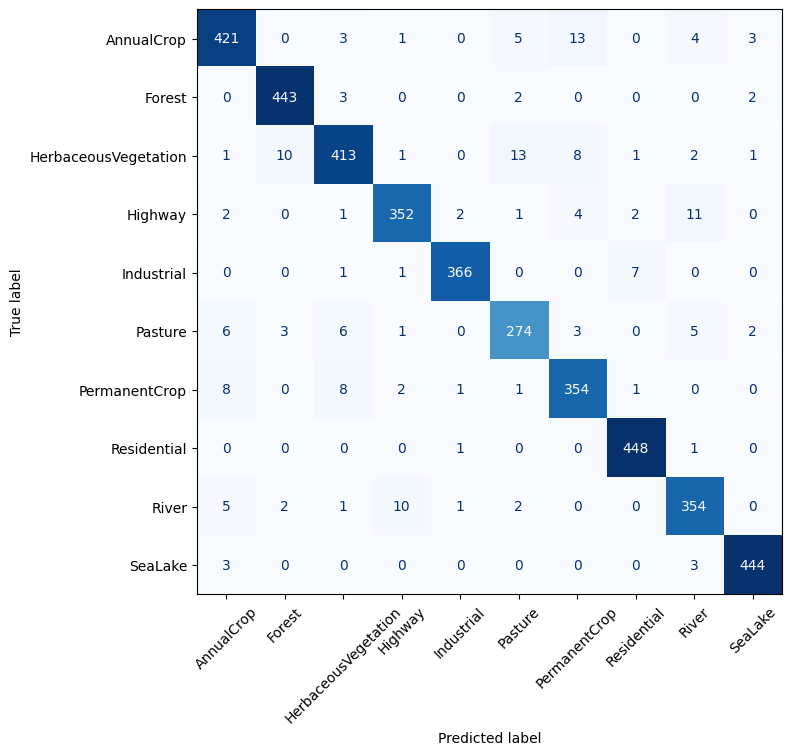

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "mobilenet_confusion.png", dpi=150)
print(RESULTS_DIR / "mobilenet_confusion.png")

/kaggle/working/AAI-521-Group4-Eurosat/results/model_b_curves.png


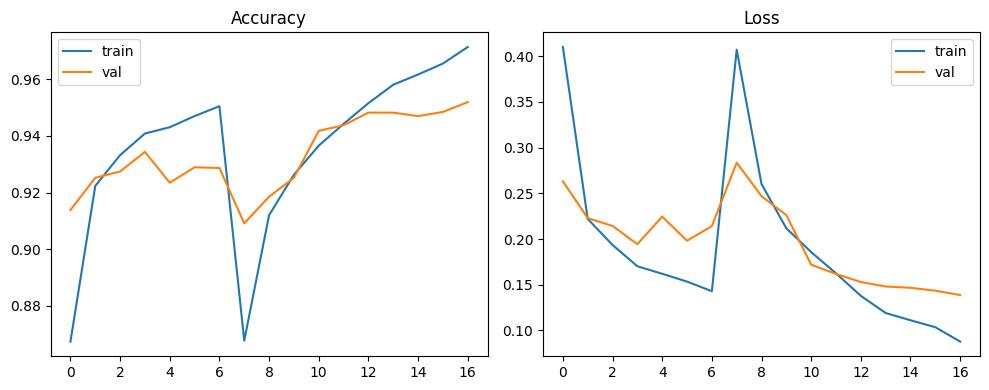

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.concat([
    pd.DataFrame(head_history.history).assign(stage="head"),
    pd.DataFrame(fine_history.history).assign(stage="fine"),
], ignore_index=True)
history.to_csv(RESULTS_DIR / "model_b_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["accuracy"], label="train")
axes[0].plot(history["val_accuracy"], label="val")
axes[0].set_title("Accuracy")
axes[0].legend()
axes[1].plot(history["loss"], label="train")
axes[1].plot(history["val_loss"], label="val")
axes[1].set_title("Loss")
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "model_b_curves.png", dpi=150)
print(RESULTS_DIR / "model_b_curves.png")

In [24]:
import pandas as pd

history = pd.concat([
    pd.DataFrame(head_history.history).assign(stage="head"),
    pd.DataFrame(fine_history.history).assign(stage="fine"),
], ignore_index=True)
history.to_csv(RESULTS_DIR / "model_b_history.csv", index=False)
print(RESULTS_DIR / "model_b_history.csv")

/kaggle/working/AAI-521-Group4-Eurosat/results/model_b_history.csv
